In [12]:
import pandas as pd
import torch
import torch.nn as nn
from pathlib import Path
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import mean_absolute_error, r2_score


folder = Path(r"C:\Users\alys_\Documents\Research\GlobalDevelopment")

# load the satellite embeddings
embeddings = pd.read_csv(
    folder / "mexico_alphaearth_2020.csv",
    dtype={"site_id": str}
)

# select the 64 satellite features
features = [f"A{i:02d}" for i in range(64)]

# remove observations with missing features
embeddings = embeddings.dropna(
    subset=features + ["irs"]).copy()

# identify municipalities
embeddings["municipio_id"] = (embeddings["site_id"].str[2:7])

print("complete observations:", len(embeddings))
print("municipalities:", embeddings["municipio_id"].nunique())

display(embeddings[["site_id", "irs"] + features[:3]].head())

complete observations: 300
municipalities: 257


,site_id,irs,A00,A01,A02
0,MX080273003,2.497399,0.020996,-0.142816,0.096897
1,MX190450458,-0.676030,0.050774,-0.146376,0.076219
2,MX050320034,-1.110565,0.058056,-0.208333,0.024035
3,MX270130016,-0.977251,0.002965,-0.144426,0.072881
4,MX070310902,1.780364,0.007909,-0.046304,0.099249


In [7]:
# split the data by municipality
split = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_idx, test_idx = next(
    split.split(
        embeddings,
        groups=embeddings["municipio_id"]
    )
)

# prepare the training data
X_train = torch.tensor(
    embeddings.iloc[train_idx][features].to_numpy(dtype="float32"))

y_train = torch.tensor(
    embeddings.iloc[train_idx]["irs"].to_numpy(dtype="float32")).reshape(-1, 1)

# prepare the test data
X_test = torch.tensor(
    embeddings.iloc[test_idx][features].to_numpy(dtype="float32"))

y_test = torch.tensor(
    embeddings.iloc[test_idx]["irs"].to_numpy(dtype="float32")).reshape(-1, 1)

print("training:", len(X_train))
print("testing:", len(X_test))

training: 237
testing: 63


In [8]:
# create the basic neural network
torch.manual_seed(42)

model = nn.Sequential(
    nn.Linear(64, 128),
    nn.ReLU(),
    nn.Linear(128, 128),
    nn.ReLU(),
    nn.Linear(128, 1)
)

loss_fn = nn.MSELoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

print(model)

Sequential(
  (0): Linear(in_features=64, out_features=128, bias=True)
  (1): ReLU()
  (2): Linear(in_features=128, out_features=128, bias=True)
  (3): ReLU()
  (4): Linear(in_features=128, out_features=1, bias=True)
)


In [9]:
# train the model
for epoch in range(200):
    model.train()

    predictions = model(X_train)
    loss = loss_fn(predictions, y_train)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    if (epoch + 1) % 50 == 0:
        print("epoch:", epoch + 1, "mse:", loss.item())

epoch: 50 mse: 0.4828067123889923
epoch: 100 mse: 0.22676308453083038
epoch: 150 mse: 0.07609565556049347
epoch: 200 mse: 0.028473958373069763


In [10]:
# predict irs for the test data
model.eval()

with torch.no_grad():
    predictions = model(X_test).numpy().ravel()

actual = y_test.numpy().ravel()

# compare against the training mean
baseline = [y_train.mean().item()] * len(actual)

print("model mae:", mean_absolute_error(actual, predictions))
print("baseline mae:", mean_absolute_error(actual, baseline))
print("model r2:", r2_score(actual, predictions))

model mae: 0.7325760126113892
baseline mae: 0.9188864827156067
model r2: 0.1684713363647461


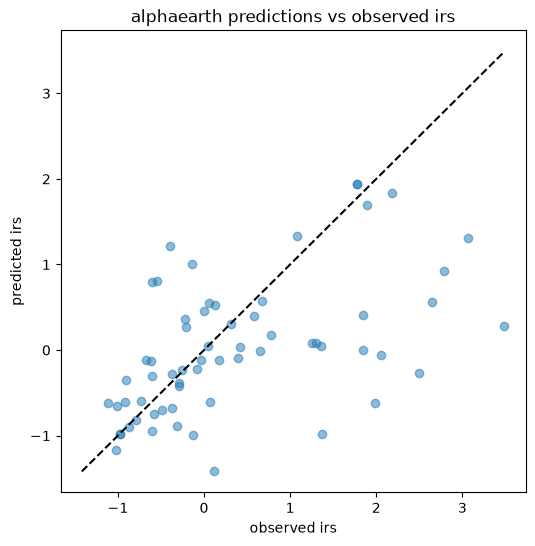

In [13]:
# compare predictions with observed irs
plt.figure(figsize=(6, 6))

plt.scatter(actual, predictions, alpha=0.5)

# show perfect predictions as a reference line
low = min(actual.min(), predictions.min())
high = max(actual.max(), predictions.max())

plt.plot([low, high], [low, high], "--", color="black")

plt.xlabel("observed irs")
plt.ylabel("predicted irs")
plt.title("alphaearth predictions vs observed irs")
plt.show()